# EN3160 - Assignment 3: Neural Networks

**Name:** Eranga W.A.O.                                                                                                    
**Index number:** 23175U

In [5]:
import copy
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torchvision import datasets, transforms, models
from torchvision.datasets.utils import download_and_extract_archive
from torch.utils.data import DataLoader
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display

In [6]:
SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
data_dir = Path("data")
results_dir = Path("results")
data_dir.mkdir(exist_ok=True)
results_dir.mkdir(exist_ok=True)

def make_loader(dataset, batch_size, shuffle=False):
    # A separate generator keeps the shuffle order independent of model size.
    generator = torch.Generator().manual_seed(SEED)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle,num_workers=0, generator=generator)

# num_workers=0 is convenient for Windows notebooks.
print("Device:", device)
print("PyTorch:", torch.__version__)
print("torchvision:", torchvision.__version__)

Device: cpu
PyTorch: 2.9.1+cpu
torchvision: 0.24.1+cpu


In [7]:
def plot_history(history, title, filename, split="test"):
    split_name = "Validation" if split == "val" else "Test"
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(history["epoch"], history["train_loss"], label="Train")
    axes[0].plot(history["epoch"], history[f"{split}_loss"], label=split_name)
    axes[0].set_title("Cross-entropy loss")
    axes[0].set_ylabel("Loss")
    axes[1].plot(history["epoch"], history["train_acc"], label="Train")
    axes[1].plot(history["epoch"], history[f"{split}_acc"], label=split_name)
    axes[1].set_title("Accuracy")
    axes[1].set_ylabel("Accuracy (%)")
    for ax in axes:
        ax.set_xlabel("Epoch")
        ax.grid(alpha=0.3)
        ax.legend()
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(results_dir / filename, dpi=150, bbox_inches="tight")
    plt.show()

## Question 1 - Dense network with manual backpropagation

### (a) Hidden layer and (b) cross-entropy loss

In [12]:
cifar_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

cifar_train = datasets.CIFAR10(root=str(data_dir), train=True,download=True, transform=cifar_transform)
cifar_test = datasets.CIFAR10(root=str(data_dir), train=False,download=True, transform=cifar_transform)

cifar_train_loader = make_loader(cifar_train, batch_size=50, shuffle=True)
cifar_train_eval_loader = make_loader(cifar_train, batch_size=256)
cifar_test_loader = make_loader(cifar_test, batch_size=256)
print("Training images:", len(cifar_train))
print("Test images:", len(cifar_test))

c:\Users\User\AppData\Local\Programs\Python\Python313\Lib\site-packages\torchvision\datasets\cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


Training images: 50000
Test images: 10000


### (c) Training for 10 epochs

In [13]:
set_seed()
Din, hidden_size, K = 3 * 32 * 32, 100, 10
W1 = torch.randn(Din, hidden_size, device=device) * np.sqrt(2 / (Din + hidden_size))
b1 = torch.zeros(hidden_size, device=device)
W2 = torch.randn(hidden_size, K, device=device) * np.sqrt(2 / (hidden_size + K))
b2 = torch.zeros(K, device=device)

dense_epochs = 10
learning_rate = 0.1
lr_decay = 0.9

In [14]:
def dense_forward(x):
    hidden = torch.sigmoid(x @ W1 + b1)
    scores = hidden @ W2 + b2
    scores = scores - scores.max(dim=1, keepdim=True).values
    log_probs = scores - torch.log(torch.exp(scores).sum(dim=1, keepdim=True))
    return hidden, log_probs

def evaluate_dense(loader):
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            x = images.to(device).flatten(1)
            labels = labels.to(device)
            _, log_probs = dense_forward(x)
            rows = torch.arange(labels.size(0), device=device)
            total_loss += (-log_probs[rows, labels]).sum().item()
            correct += (log_probs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)
    return total_loss / total, 100 * correct / total

In [ ]:
dense_rows = []
lr = learning_rate

for epoch in range(dense_epochs):
    for images, labels in cifar_train_loader:
        x = images.to(device).flatten(1)
        labels = labels.to(device)
        N = labels.size(0)

        # Forward pass and mean cross-entropy loss.
        hidden, log_probs = dense_forward(x)
        rows = torch.arange(N, device=device)
        loss = -log_probs[rows, labels].mean()

        # Manual backward pass: dL/dZ = (P - Y) / N.
        dscores = log_probs.exp()
        dscores[rows, labels] -= 1
        dscores /= N
        dW2 = hidden.T @ dscores
        db2 = dscores.sum(dim=0)
        dhidden = (dscores @ W2.T) * hidden * (1 - hidden)
        dW1 = x.T @ dhidden
        db1 = dhidden.sum(dim=0)

        # Calculate every gradient before changing any weight.
        W1 -= lr * dW1
        b1 -= lr * db1
        W2 -= lr * dW2
        b2 -= lr * db2

    train_loss, train_acc = evaluate_dense(cifar_train_eval_loader)
    test_loss, test_acc = evaluate_dense(cifar_test_loader)
    dense_rows.append({"epoch": epoch + 1, "lr": lr,
                       "train_loss": train_loss, "test_loss": test_loss,
                       "train_acc": train_acc, "test_acc": test_acc})
    print(f"Epoch {epoch + 1:2d}/{dense_epochs} | "
          f"Train loss {train_loss:.4f}, accuracy {train_acc:.2f}% | "
          f"Test loss {test_loss:.4f}, accuracy {test_acc:.2f}%")
    lr *= lr_decay

dense_history = pd.DataFrame(dense_rows)
dense_history.to_csv(results_dir / "q1_dense_history.csv", index=False)

Epoch  1/10 | Train loss 1.6871, accuracy 41.67% | Test loss 1.7048, accuracy 41.50%


,epoch,lr,train_loss,test_loss,train_acc,test_acc
0,1,0.1000,1.6871,1.7048,41.672,41.50
1,2,0.0900,1.6186,1.6522,44.430,42.59
2,3,0.0810,1.5635,1.6174,46.452,44.02
3,4,0.0729,1.5169,1.5845,47.786,45.23
4,5,0.0656,1.4784,1.5644,49.628,46.03
5,6,0.0590,1.4452,1.5421,50.656,46.56
6,7,0.0531,1.4326,1.5452,50.748,46.47
7,8,0.0478,1.3946,1.5192,52.354,47.49
8,9,0.0430,1.3782,1.5189,52.928,47.66
9,10,0.0387,1.3561,1.5083,53.712,47.80


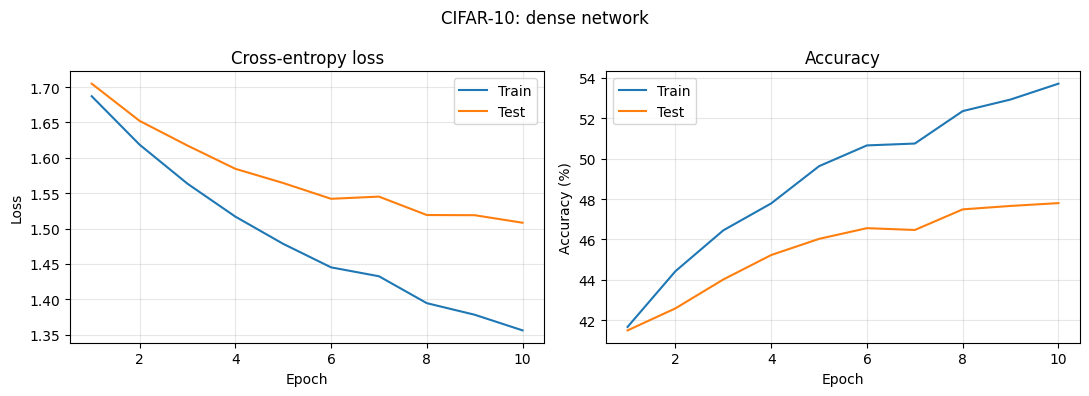

Training accuracy after 10 epochs: 53.71%
Test accuracy after 10 epochs: 47.80%
Train minus test accuracy: 5.91 percentage points


In [ ]:
display(dense_history.round(4))
plot_history(dense_history, "CIFAR-10: dense network", "q1_dense_curves.png")

dense_final = dense_history.iloc[-1]
print(f"Training accuracy after 10 epochs: {dense_final['train_acc']:.2f}%")
print(f"Test accuracy after 10 epochs: {dense_final['test_acc']:.2f}%")
print(f"Train minus test accuracy: "f"{dense_final['train_acc'] - dense_final['test_acc']:.2f} percentage points")

## Question 2 - LeNet-5 and a small CNN on MNIST

In [ ]:
mnist_transform = transforms.Compose([
    transforms.Pad(2),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])
mnist_train = datasets.MNIST(root=str(data_dir), train=True,download=True, transform=mnist_transform)
mnist_test = datasets.MNIST(root=str(data_dir), train=False,download=True, transform=mnist_transform)
mnist_train_eval_loader = make_loader(mnist_train, batch_size=256)
mnist_test_loader = make_loader(mnist_test, batch_size=256)

mnist_epochs = 10
mnist_batch_size = 64
mnist_lr = 0.001
criterion = nn.CrossEntropyLoss()
print("Training images:", len(mnist_train))
print("Test images:", len(mnist_test))

100.0%
100.0%
100.0%
100.0%


Training images: 60000
Test images: 10000


### (a) LeNet-5

In [10]:
class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 6, kernel_size=5)
        self.conv2 = nn.Conv2d(6, 16, kernel_size=5)
        self.pool = nn.AvgPool2d(kernel_size=2, stride=2)
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = self.pool(torch.tanh(self.conv1(x)))
        x = self.pool(torch.tanh(self.conv2(x)))
        x = torch.flatten(x, 1)
        x = torch.tanh(self.fc1(x))
        x = torch.tanh(self.fc2(x))
        return self.fc3(x)  # Raw scores; CrossEntropyLoss handles log-softmax.

### (b) Modern small CNN

In [11]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.25)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

### (c) Training, plots and confusion matrices

In [12]:
def train_one_epoch(model, loader, optimizer, frozen_features=False):
    model.train()
    if frozen_features:
        # Keep the backbone's batch-normalization statistics fixed in Q3.
        model.eval()
        model.fc.train()

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        scores = model(images)
        loss = criterion(scores, labels)
        loss.backward()
        optimizer.step()

def evaluate(model, loader):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    true_labels, predictions = [], []
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            scores = model(images)
            loss = criterion(scores, labels)
            predicted = scores.argmax(dim=1)
            total_loss += loss.item() * labels.size(0)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)
            true_labels.extend(labels.cpu().tolist())
            predictions.extend(predicted.cpu().tolist())
    return total_loss / total, 100 * correct / total, true_labels, predictions

In [13]:
def train_mnist(model_class, name):
    set_seed()
    model = model_class().to(device)
    # Recreate this loader so both models get the same shuffled batches.
    train_loader = make_loader(mnist_train, mnist_batch_size, shuffle=True)
    optimizer = optim.Adam(model.parameters(), lr=mnist_lr)
    rows = []
    start = time.perf_counter()

    for epoch in range(mnist_epochs):
        train_one_epoch(model, train_loader, optimizer)
        train_loss, train_acc, _, _ = evaluate(model, mnist_train_eval_loader)
        test_loss, test_acc, _, _ = evaluate(model, mnist_test_loader)
        rows.append({"epoch": epoch + 1,
                     "train_loss": train_loss, "test_loss": test_loss,
                     "train_acc": train_acc, "test_acc": test_acc})
        print(f"{name} | Epoch {epoch + 1:2d}/{mnist_epochs} | "
              f"Train loss {train_loss:.4f}, accuracy {train_acc:.2f}% | "
              f"Test loss {test_loss:.4f}, accuracy {test_acc:.2f}%")

    elapsed = time.perf_counter() - start
    history = pd.DataFrame(rows)
    return model, history, elapsed

In [14]:
lenet, lenet_history, lenet_seconds = train_mnist(LeNet5, "LeNet-5")
lenet_history.to_csv(results_dir / "q2_lenet_history.csv", index=False)

LeNet-5 | Epoch  1/10 | Train loss 0.0998, accuracy 96.98% | Test loss 0.0974, accuracy 96.87%
LeNet-5 | Epoch  2/10 | Train loss 0.0559, accuracy 98.23% | Test loss 0.0648, accuracy 97.93%
LeNet-5 | Epoch  3/10 | Train loss 0.0438, accuracy 98.62% | Test loss 0.0618, accuracy 97.99%
LeNet-5 | Epoch  4/10 | Train loss 0.0380, accuracy 98.80% | Test loss 0.0552, accuracy 98.32%
LeNet-5 | Epoch  5/10 | Train loss 0.0283, accuracy 99.12% | Test loss 0.0518, accuracy 98.30%
LeNet-5 | Epoch  6/10 | Train loss 0.0206, accuracy 99.36% | Test loss 0.0446, accuracy 98.66%
LeNet-5 | Epoch  7/10 | Train loss 0.0255, accuracy 99.18% | Test loss 0.0488, accuracy 98.50%
LeNet-5 | Epoch  8/10 | Train loss 0.0157, accuracy 99.50% | Test loss 0.0447, accuracy 98.63%
LeNet-5 | Epoch  9/10 | Train loss 0.0147, accuracy 99.52% | Test loss 0.0476, accuracy 98.64%
LeNet-5 | Epoch 10/10 | Train loss 0.0163, accuracy 99.44% | Test loss 0.0496, accuracy 98.52%


In [15]:
small_cnn, cnn_history, cnn_seconds = train_mnist(SmallCNN, "Small CNN")
cnn_history.to_csv(results_dir / "q2_small_cnn_history.csv", index=False)

Small CNN | Epoch  1/10 | Train loss 0.0471, accuracy 98.49% | Test loss 0.0445, accuracy 98.48%
Small CNN | Epoch  2/10 | Train loss 0.0355, accuracy 98.88% | Test loss 0.0334, accuracy 98.93%
Small CNN | Epoch  3/10 | Train loss 0.0246, accuracy 99.17% | Test loss 0.0273, accuracy 99.00%
Small CNN | Epoch  4/10 | Train loss 0.0270, accuracy 99.14% | Test loss 0.0326, accuracy 99.02%
Small CNN | Epoch  5/10 | Train loss 0.0163, accuracy 99.51% | Test loss 0.0278, accuracy 99.11%
Small CNN | Epoch  6/10 | Train loss 0.0146, accuracy 99.54% | Test loss 0.0240, accuracy 99.17%
Small CNN | Epoch  7/10 | Train loss 0.0120, accuracy 99.64% | Test loss 0.0215, accuracy 99.24%
Small CNN | Epoch  8/10 | Train loss 0.0118, accuracy 99.62% | Test loss 0.0237, accuracy 99.29%
Small CNN | Epoch  9/10 | Train loss 0.0158, accuracy 99.48% | Test loss 0.0274, accuracy 99.09%
Small CNN | Epoch 10/10 | Train loss 0.0085, accuracy 99.74% | Test loss 0.0232, accuracy 99.36%


,epoch,train_loss,test_loss,train_acc,test_acc
0,1,0.0998,0.0974,96.9800,96.87
1,2,0.0559,0.0648,98.2317,97.93
2,3,0.0438,0.0618,98.6183,97.99
3,4,0.0380,0.0552,98.7967,98.32
4,5,0.0283,0.0518,99.1250,98.30
5,6,0.0206,0.0446,99.3617,98.66
6,7,0.0255,0.0488,99.1767,98.50
7,8,0.0157,0.0447,99.5050,98.63
8,9,0.0147,0.0476,99.5167,98.64
9,10,0.0163,0.0496,99.4400,98.52


,epoch,train_loss,test_loss,train_acc,test_acc
0,1,0.0471,0.0445,98.4933,98.48
1,2,0.0355,0.0334,98.8767,98.93
2,3,0.0246,0.0273,99.1733,99.00
3,4,0.0270,0.0326,99.1400,99.02
4,5,0.0163,0.0278,99.5133,99.11
5,6,0.0146,0.0240,99.5400,99.17
6,7,0.0120,0.0215,99.6350,99.24
7,8,0.0118,0.0237,99.6250,99.29
8,9,0.0158,0.0274,99.4817,99.09
9,10,0.0085,0.0232,99.7400,99.36


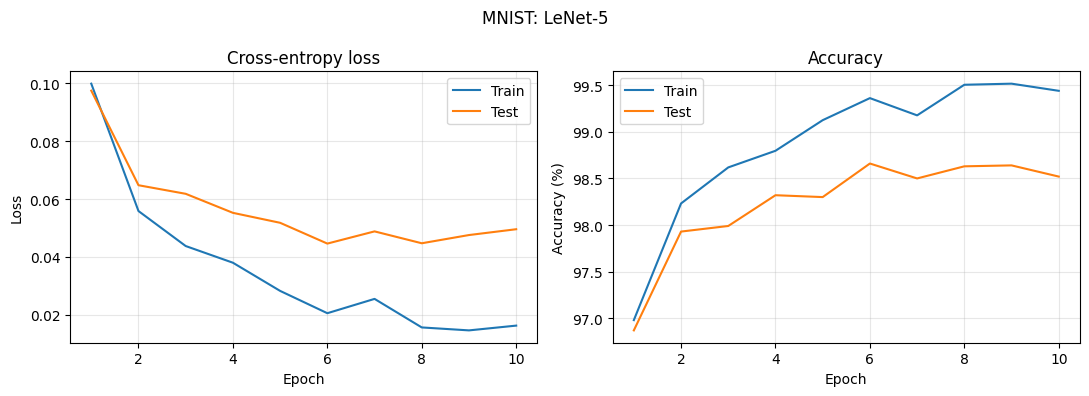

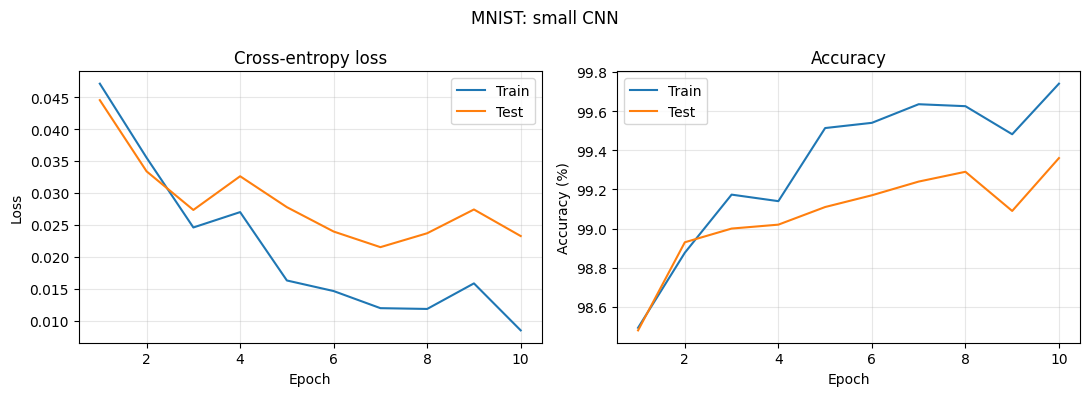

,Model,Parameters,Train loss,Test loss,Train accuracy (%),Test accuracy (%),Train-test gap (pp),Train + evaluation time (s)
0,LeNet-5,61706,0.0163,0.0496,99.44,98.52,0.92,821.6216
1,Small CNN,155898,0.0085,0.0232,99.74,99.36,0.38,1753.8659


In [16]:
display(lenet_history.round(4))
display(cnn_history.round(4))
plot_history(lenet_history, "MNIST: LeNet-5", "q2_lenet_curves.png")
plot_history(cnn_history, "MNIST: small CNN", "q2_small_cnn_curves.png")

mnist_rows = []
for name, model, history, seconds in [
    ("LeNet-5", lenet, lenet_history, lenet_seconds),
    ("Small CNN", small_cnn, cnn_history, cnn_seconds)
]:
    last = history.iloc[-1]
    mnist_rows.append({
        "Model": name,
        "Parameters": sum(p.numel() for p in model.parameters()),
        "Train loss": last["train_loss"], "Test loss": last["test_loss"],
        "Train accuracy (%)": last["train_acc"],
        "Test accuracy (%)": last["test_acc"],
        "Train-test gap (pp)": last["train_acc"] - last["test_acc"],
        "Train + evaluation time (s)": seconds
    })
mnist_results = pd.DataFrame(mnist_rows)
display(mnist_results.round(4))
mnist_results.to_csv(results_dir / "q2_comparison.csv", index=False)

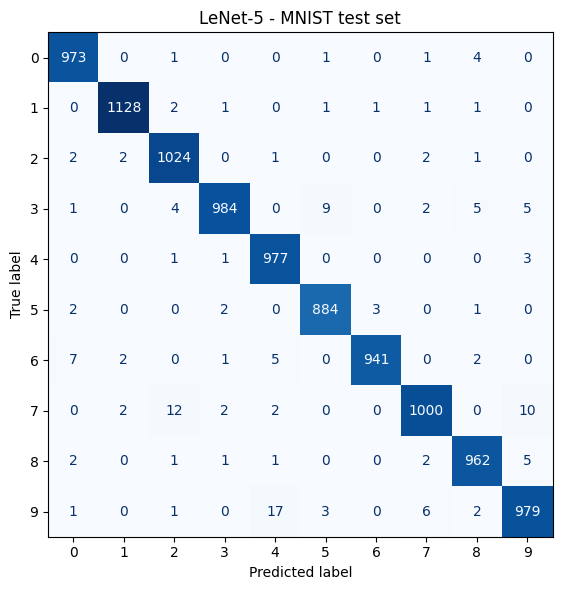

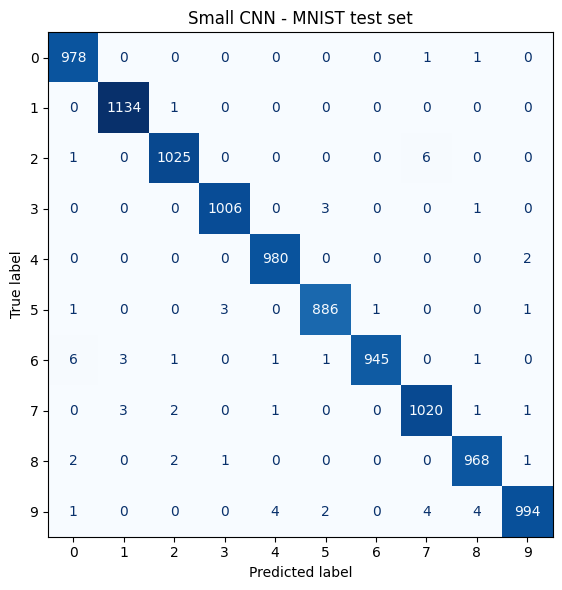

In [17]:
def show_confusion(true_labels, predictions, class_names, title, filename):
    cm = confusion_matrix(true_labels, predictions, labels=range(len(class_names)))
    fig, ax = plt.subplots(figsize=(7, 6))
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(results_dir / filename, dpi=150, bbox_inches="tight")
    plt.show()
    return cm

mnist_confusions = {}
for name, model, filename in [
    ("LeNet-5", lenet, "q2_lenet_confusion.png"),
    ("Small CNN", small_cnn, "q2_small_cnn_confusion.png")
]:
    _, _, true_labels, predictions = evaluate(model, mnist_test_loader)
    cm = show_confusion(true_labels, predictions, list(range(10)),
                        name + " - MNIST test set", filename)
    mnist_confusions[name] = cm
    pd.DataFrame(cm, index=range(10), columns=range(10)).to_csv(
        results_dir / filename.replace(".png", ".csv"), index_label="True digit")

Rows of each confusion matrix are the true classes and columns are the
predicted classes. Diagonal entries are correct predictions. The below
images show a fixed selection of examples, so both models see the same images.

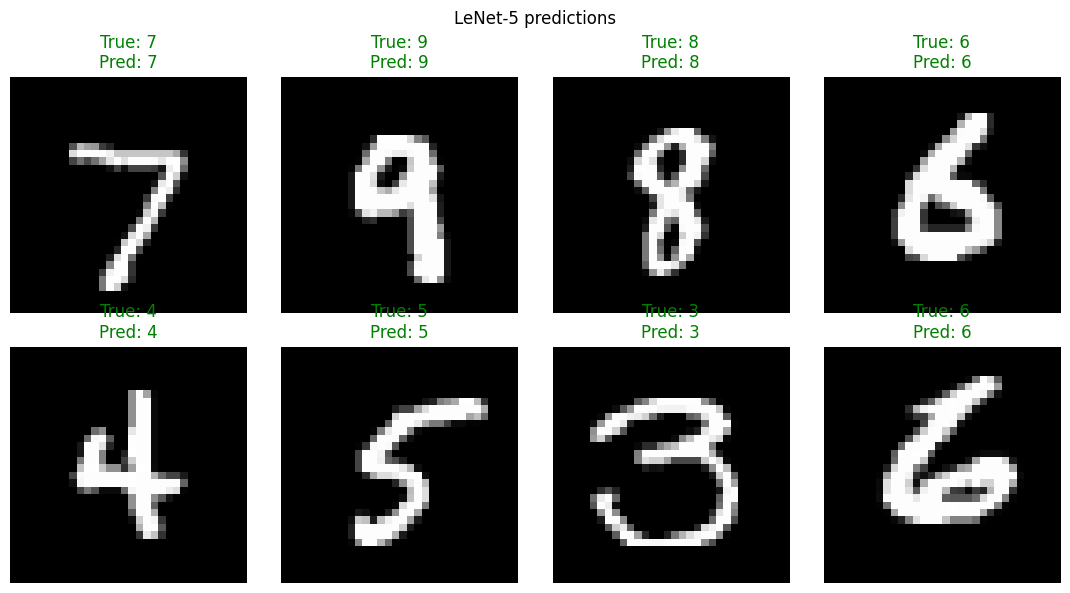

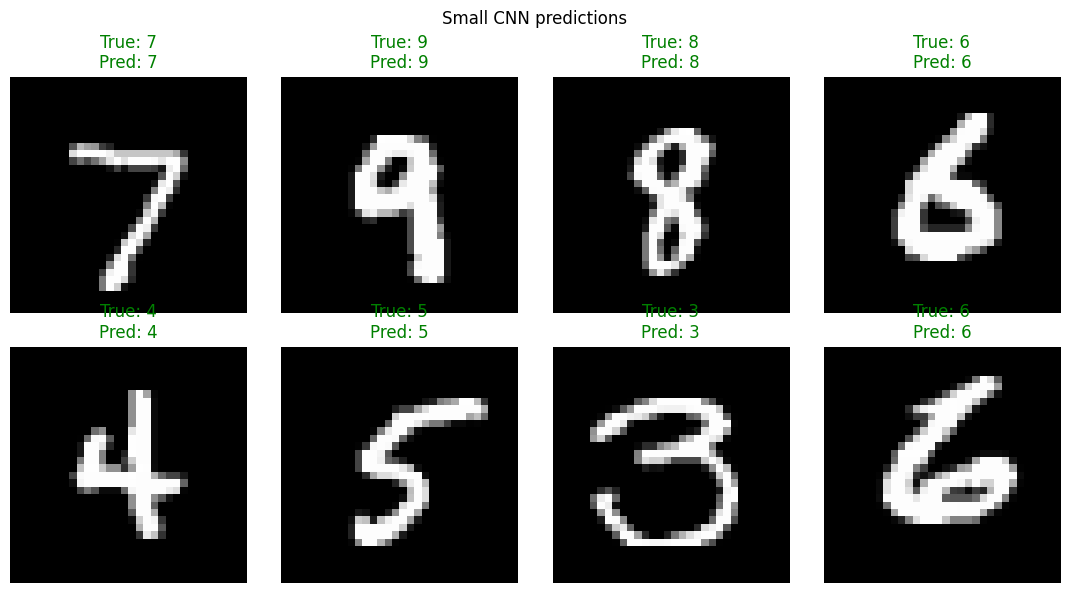

In [ ]:
def show_predictions(model, dataset, class_names, mean, std, title, filename):
    model.eval()
    indices = np.linspace(0, len(dataset) - 1, 8, dtype=int)
    mean = torch.tensor(mean).view(-1, 1, 1)
    std = torch.tensor(std).view(-1, 1, 1)
    fig, axes = plt.subplots(2, 4, figsize=(11, 6))
    with torch.no_grad():
        for ax, index in zip(axes.flat, indices):
            image, label = dataset[int(index)]
            predicted = model(image.unsqueeze(0).to(device)).argmax(1).item()
            image = (image * std + mean).clamp(0, 1)
            if image.shape[0] == 1:
                ax.imshow(image.squeeze(0), cmap="gray", vmin=0, vmax=1)
            else:
                ax.imshow(image.permute(1, 2, 0))
            color = "green" if predicted == label else "red"
            ax.set_title(f"True: {class_names[label]}\nPred: {class_names[predicted]}",color=color)
            ax.axis("off")
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(results_dir / filename, dpi=150, bbox_inches="tight")
    plt.show()

show_predictions(lenet, mnist_test, list(range(10)), [0.5], [0.5],"LeNet-5 predictions", "q2_lenet_predictions.png")
show_predictions(small_cnn, mnist_test, list(range(10)), [0.5], [0.5],"Small CNN predictions", "q2_small_cnn_predictions.png")

In [ ]:
difference = cnn_history.iloc[-1]["test_acc"] - lenet_history.iloc[-1]["test_acc"]
print(f"Small CNN minus LeNet-5 test accuracy: {difference:+.2f} percentage points.")

for name, cm in mnist_confusions.items():
    mistakes = cm.copy()
    np.fill_diagonal(mistakes, 0)
    if mistakes.max() > 0:
        true_digit, predicted_digit = np.unravel_index(mistakes.argmax(), mistakes.shape)
        print(f"{name}: a most frequent error is {true_digit} predicted as "
              f"{predicted_digit}, with {mistakes.max()} examples.")
    else:
        print(f"{name}: no test errors.")

Small CNN minus LeNet-5 test accuracy: +0.84 percentage points.
LeNet-5: a most frequent error is 9 predicted as 4, with 17 examples.
Small CNN: a most frequent error is 2 predicted as 7, with 6 examples.


### Discussion

LeNet-5 uses tanh and average pooling; the small CNN uses ReLU, max pooling, batch normalization, and dropout. Their parameter counts also differ, so no single feature explains an accuracy difference. Compare the final test results and confusion matrices for overfitting and common digit errors. One seeded run cannot establish which model is consistently better.

## Question 3 - Transfer learning with ResNet18

In [8]:
hymenoptera_dir = data_dir / "hymenoptera_data"
if not (hymenoptera_dir / "train").is_dir() or not (hymenoptera_dir / "val").is_dir():
    download_and_extract_archive("https://download.pytorch.org/tutorial/hymenoptera_data.zip",download_root=str(data_dir), extract_root=str(data_dir))

imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]
transfer_train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std)
])
transfer_eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std)
])

ants_bees_train = datasets.ImageFolder(hymenoptera_dir / "train",transform=transfer_train_transform)
ants_bees_train_eval = datasets.ImageFolder(hymenoptera_dir / "train",transform=transfer_eval_transform)
ants_bees_val = datasets.ImageFolder(hymenoptera_dir / "val",transform=transfer_eval_transform)
class_names = ants_bees_train.classes
assert ants_bees_train.class_to_idx == ants_bees_val.class_to_idx

transfer_train_eval_loader = make_loader(ants_bees_train_eval, batch_size=16)
transfer_val_loader = make_loader(ants_bees_val, batch_size=16)
transfer_epochs = 25
print("Classes:", class_names)
print("Training images:", len(ants_bees_train))
print("Validation images:", len(ants_bees_val))

Classes: ['ants', 'bees']
Training images: 244
Validation images: 153


### (a) Fine-tuning and (b) feature extraction

In [9]:
set_seed()
base_resnet = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
base_resnet.fc = nn.Linear(base_resnet.fc.in_features, len(class_names))

finetune_model = copy.deepcopy(base_resnet).to(device)
feature_model = copy.deepcopy(base_resnet).to(device)
del base_resnet

for parameter in feature_model.parameters():
    parameter.requires_grad = False
for parameter in feature_model.fc.parameters():
    parameter.requires_grad = True

print("Fine-tuning trainable parameters:",sum(p.numel() for p in finetune_model.parameters() if p.requires_grad))
print("Feature-extraction trainable parameters:",sum(p.numel() for p in feature_model.parameters() if p.requires_grad))

Fine-tuning trainable parameters: 11177538
Feature-extraction trainable parameters: 1026


In [10]:
def train_transfer(model, name, frozen_features=False):
    set_seed()
    train_loader = make_loader(ants_bees_train, batch_size=4, shuffle=True)
    parameters = [p for p in model.parameters() if p.requires_grad]
    optimizer = optim.SGD(parameters, lr=0.001, momentum=0.9)
    scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=7, gamma=0.1)
    rows = []
    best_acc = -1.0
    best_epoch = 0
    best_weights = copy.deepcopy(model.state_dict())
    start = time.perf_counter()

    for epoch in range(transfer_epochs):
        current_lr = optimizer.param_groups[0]["lr"]
        train_one_epoch(model, train_loader, optimizer, frozen_features)
        train_loss, train_acc, _, _ = evaluate(model, transfer_train_eval_loader)
        val_loss, val_acc, _, _ = evaluate(model, transfer_val_loader)
        rows.append({"epoch": epoch + 1, "lr": current_lr,
                     "train_loss": train_loss, "val_loss": val_loss,
                     "train_acc": train_acc, "val_acc": val_acc})
        print(f"{name} | Epoch {epoch + 1:2d}/{transfer_epochs} | "
              f"Train loss {train_loss:.4f}, accuracy {train_acc:.2f}% | "
              f"Val loss {val_loss:.4f}, accuracy {val_acc:.2f}%")

        if val_acc > best_acc:
            best_acc = val_acc
            best_epoch = epoch + 1
            best_weights = copy.deepcopy(model.state_dict())
        scheduler.step()

    elapsed = time.perf_counter() - start
    history = pd.DataFrame(rows)
    # Restore the first epoch with the highest validation accuracy.
    model.load_state_dict(best_weights)
    best_train_loss, best_train_acc, _, _ = evaluate(model, transfer_train_eval_loader)
    best_val_loss, best_val_acc, _, _ = evaluate(model, transfer_val_loader)
    result = {
        "Method": name, "Epochs": transfer_epochs,
        "Trainable parameters": sum(p.numel() for p in parameters),
        "Final train accuracy (%)": history.iloc[-1]["train_acc"],
        "Final validation accuracy (%)": history.iloc[-1]["val_acc"],
        "Best epoch": best_epoch,
        "Best-checkpoint train loss": best_train_loss,
        "Best-checkpoint validation loss": best_val_loss,
        "Best-checkpoint train accuracy (%)": best_train_acc,
        "Best-checkpoint validation accuracy (%)": best_val_acc,
        "Train + evaluation time (s)": elapsed
    }
    return model, history, result

In [ ]:
finetune_model, finetune_history, finetune_result = train_transfer(
    finetune_model, "Fine-tuning")
finetune_history.to_csv(results_dir / "q3_finetuning_history.csv", index=False)

In [ ]:
feature_model, feature_history, feature_result = train_transfer(
    feature_model, "Feature extraction", frozen_features=True)
feature_history.to_csv(results_dir / "q3_feature_history.csv", index=False)

In [ ]:
display(finetune_history.round(4))
display(feature_history.round(4))
plot_history(finetune_history, "ResNet18: fine-tuning",
             "q3_finetuning_curves.png", split="val")
plot_history(feature_history, "ResNet18: feature extraction",
             "q3_feature_curves.png", split="val")

transfer_results = pd.DataFrame([finetune_result, feature_result]).set_index("Method")
# Transposing keeps the comparison readable in a notebook/PDF.
display(transfer_results.T.round(4))
transfer_results.to_csv(results_dir / "q3_comparison.csv")

In [ ]:
for name, model, prefix in [
    ("Fine-tuning", finetune_model, "q3_finetuning"),
    ("Feature extraction", feature_model, "q3_feature")
]:
    _, _, true_labels, predictions = evaluate(model, transfer_val_loader)
    cm = show_confusion(true_labels, predictions, class_names,
                        name + " - validation set", prefix + "_confusion.png")
    pd.DataFrame(cm, index=class_names, columns=class_names).to_csv(
        results_dir / (prefix + "_confusion.csv"), index_label="True class")
    show_predictions(model, ants_bees_val, class_names, imagenet_mean, imagenet_std,
                     name + " predictions", prefix + "_predictions.png")

In [ ]:
fine_acc = finetune_result["Best-checkpoint validation accuracy (%)"]
feature_acc = feature_result["Best-checkpoint validation accuracy (%)"]
print(f"Fine-tuning best validation accuracy: {fine_acc:.2f}% "
      f"at epoch {finetune_result['Best epoch']}.")
print(f"Feature extraction best validation accuracy: {feature_acc:.2f}% "
      f"at epoch {feature_result['Best epoch']}.")
print(f"Fine-tuning minus feature extraction: {fine_acc - feature_acc:+.2f} "
      "percentage points at their selected checkpoints.")

for result in [finetune_result, feature_result]:
    gap = (result["Best-checkpoint train accuracy (%)"]
           - result["Best-checkpoint validation accuracy (%)"])
    print(f"{result['Method']}: train minus validation accuracy is {gap:.2f} "
          "percentage points at the selected checkpoint.")